# 01 · Data profiling

**Project:** Banking Transaction Analytics (Berka `financial` data)
**Goal:** understand the raw data before touching it: structure, missing values, keys, date ranges, distributions, and how well the data follows its own rules.

**Rules for this notebook**
- The raw CSV files in `data/raw/` are only **read**, never modified.
- Every check is written to a log. A **FAIL** means the data (or our understanding of it) is broken and the notebook stops at the end. A **FINDING** means something unusual that needs a decision in the cleaning notebook.
- Nothing is cleaned or deleted here.

Run it with the `banking` conda environment (VS Code: pick the `banking` kernel, then **Run All**).

In [23]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)


def find_project_root(start: Path) -> Path:
    """Walk up from the current folder until we find data/raw."""
    for folder in [start, *start.parents]:
        if (folder / "data" / "raw").exists():
            return folder
    raise FileNotFoundError("Could not find data/raw. Run scripts/download_berka.py first.")


ROOT = find_project_root(Path.cwd())
RAW = ROOT / "data" / "raw"
REPORTS = ROOT / "reports"
print("Project root:", ROOT)

Project root: c:\Users\acer\Documents\banking-transaction-analytics


In [24]:
checks = []


def check(name, passed, detail="", hard=True):
    """Record one check.
    hard=True  -> a failure is a FAIL (the data or our understanding is broken).
    hard=False -> a failure is a FINDING (unusual, needs a decision later).
    """
    passed = bool(passed)
    status = "PASS" if passed else ("FAIL" if hard else "FINDING")
    checks.append({"check": name, "status": status, "detail": detail})
    print(f"[{status}] {name}" + (f"  ({detail})" if detail else ""))

## 1. Load the raw data and reconcile it with the download manifest
The download script saved how many rows each table had on the server. Our loaded tables must match.

In [25]:
manifest = pd.read_csv(RAW / "_download_manifest.csv")
SMALL_TABLES = ["account", "card", "client", "disp", "district", "loan", "order"]

shown = [c for c in ["database", "table", "rows_expected", "rows_written", "downloaded_at_utc"] if c in manifest.columns]
print(manifest[shown].to_string(index=False))

if "database" in manifest.columns:
    check("All tables were downloaded from the 'financial' database", set(manifest["database"]) == {"financial"})
else:
    check(
        "Manifest records the source database",
        False,
        "no 'database' column: the manifest was written by an older version of the download script",
        hard=False,
    )
check(
    "Manifest lists exactly the 8 'financial' tables",
    set(manifest["table"]) == set(SMALL_TABLES + ["trans"]),
    str(sorted(manifest["table"])),
)

tables = {name: pd.read_csv(RAW / f"{name}.csv") for name in SMALL_TABLES}

# trans has about a million rows: use compact types to keep memory low.
trans = pd.read_csv(
    RAW / "trans.csv",
    dtype={
        "trans_id": "int32",
        "account_id": "int32",
        "type": "category",
        "operation": "category",
        "k_symbol": "category",
        "bank": "category",
    },
    parse_dates=["date"],
    low_memory=False,  # parse the whole file at once so each category column gets one consistent type
)
tables["trans"] = trans
print(f"\ntrans uses about {trans.memory_usage(deep=True).sum() / 1e6:,.0f} MB in memory")

   table  rows_expected  rows_written         downloaded_at_utc
 account           4500          4500 2026-10-12T18:50:37+00:00
    card            892           892 2026-10-12T18:50:38+00:00
  client           5369          5369 2026-10-12T18:50:41+00:00
    disp           5369          5369 2026-10-12T18:50:44+00:00
district             77            77 2026-10-12T18:50:45+00:00
    loan            682           682 2026-10-12T18:50:47+00:00
   order           6471          6471 2026-10-12T18:50:49+00:00
   trans        1056320       1056320 2026-10-12T18:54:29+00:00
[FINDING] Manifest records the source database  (no 'database' column: the manifest was written by an older version of the download script)
[PASS] Manifest lists exactly the 8 'financial' tables  (['account', 'card', 'client', 'disp', 'district', 'loan', 'order', 'trans'])

trans uses about 46 MB in memory


In [26]:
expected_rows = manifest.set_index("table")["rows_written"]
for name, df in tables.items():
    expected = expected_rows.get(name)
    check(f"{name}: row count matches the manifest", expected is not None and len(df) == expected, f"{len(df):,} rows")
    key = df.columns[0]
    check(f"{name}: {key} is unique", df[key].is_unique)

client_columns = set(tables["client"].columns)
check(
    "Loaded data has the 'financial' schema (client has gender and birth_date, no birth_number)",
    {"gender", "birth_date"} <= client_columns and "birth_number" not in client_columns,
)

[PASS] account: row count matches the manifest  (4,500 rows)
[PASS] account: account_id is unique
[PASS] card: row count matches the manifest  (892 rows)
[PASS] card: card_id is unique
[PASS] client: row count matches the manifest  (5,369 rows)
[PASS] client: client_id is unique
[PASS] disp: row count matches the manifest  (5,369 rows)
[PASS] disp: disp_id is unique
[PASS] district: row count matches the manifest  (77 rows)
[PASS] district: district_id is unique
[PASS] loan: row count matches the manifest  (682 rows)
[PASS] loan: loan_id is unique
[PASS] order: row count matches the manifest  (6,471 rows)
[PASS] order: order_id is unique
[PASS] trans: row count matches the manifest  (1,056,320 rows)
[PASS] trans: trans_id is unique
[PASS] Loaded data has the 'financial' schema (client has gender and birth_date, no birth_number)


In [27]:
# Parse the remaining date columns. Any value that cannot be parsed is a FAIL.
DATE_COLUMNS = {"account": ["date"], "card": ["issued"], "client": ["birth_date"], "loan": ["date"]}
for table, columns in DATE_COLUMNS.items():
    for col in columns:
        parsed = pd.to_datetime(tables[table][col], errors="coerce")
        check(
            f"{table}.{col} parses as a date",
            parsed.notna().all(),
            f"{parsed.min().date()} to {parsed.max().date()}",
        )
        tables[table][col] = parsed

check("trans.date has no missing values", trans["date"].notna().all(), f"{trans['date'].min().date()} to {trans['date'].max().date()}")

[PASS] account.date parses as a date  (1993-01-01 to 1997-12-29)
[PASS] card.issued parses as a date  (1993-11-07 to 1998-12-29)
[PASS] client.birth_date parses as a date  (1911-08-20 to 1987-09-27)
[PASS] loan.date parses as a date  (1993-07-05 to 1998-12-08)
[PASS] trans.date has no missing values  (1993-01-01 to 1998-12-31)


## 2. Structure, missing values and distinct counts

In [28]:
rows = []
for name, df in tables.items():
    for col in df.columns:
        rows.append(
            {
                "table": name,
                "column": col,
                "dtype": str(df[col].dtype),
                "missing": int(df[col].isna().sum()),
                "missing_pct": df[col].isna().mean() * 100,
                "distinct": int(df[col].nunique()),
            }
        )
profile = pd.DataFrame(rows)
profile

,table,column,dtype,missing,missing_pct,distinct
0,account,account_id,int64,0,0.00,4500
1,account,district_id,int64,0,0.00,77
2,account,frequency,str,0,0.00,3
3,account,date,datetime64[us],0,0.00,1535
4,card,card_id,int64,0,0.00,892
5,card,disp_id,int64,0,0.00,892
6,card,type,str,0,0.00,3
7,card,issued,datetime64[us],0,0.00,607
8,client,client_id,int64,0,0.00,5369
9,client,gender,str,0,0.00,2


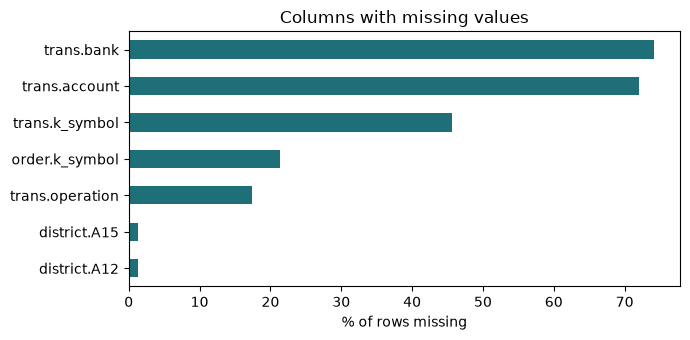

In [29]:
missing = profile[profile["missing"] > 0].copy()
if missing.empty:
    print("No missing values in any table.")
else:
    missing["label"] = missing["table"] + "." + missing["column"]
    ax = missing.sort_values("missing_pct").plot.barh(
        x="label", y="missing_pct", legend=False, figsize=(7, 3.5), color="#1f6f78"
    )
    ax.set_xlabel("% of rows missing")
    ax.set_ylabel("")
    ax.set_title("Columns with missing values")
    plt.tight_layout()
    plt.show()

In [30]:
# Numeric distributions of the money tables (ID-like columns excluded).
for name in ["trans", "loan", "order"]:
    df = tables[name]
    drop = [c for c in df.columns if c.endswith("_id")] + ["account", "account_to"]
    numeric = df.select_dtypes("number").drop(columns=drop, errors="ignore")
    print(f"\n{name}")
    display(numeric.describe(percentiles=[0.01, 0.5, 0.99]).T)


trans


,count,mean,std,min,1%,50%,99%,max
amount,"1,056,320.00","5,924.21","9,522.70",0.00,15.00,"2,100.00","45,454.81","87,400.00"
balance,"1,056,320.00","38,518.38","22,117.87","-41,126.00","3,483.38","33,143.00","108,334.81","209,637.00"



loan


,count,mean,std,min,1%,50%,99%,max
amount,682.00,"151,410.18","113,372.41","4,980.00","12,387.24","116,928.00","477,059.40","590,820.00"
duration,682.00,36.49,17.08,12.00,12.00,36.00,60.00,60.00
payments,682.00,"4,190.66","2,215.83",304.00,412.72,"3,934.00","9,301.44","9,910.00"



order


,count,mean,std,min,1%,50%,99%,max
amount,"6,471.00","3,280.64","2,714.48",1.00,17.70,"2,596.00","11,966.00","14,882.00"


## 3. Relationships and integrity
Hard checks: if one of these fails, joins in the SQL and Power BI work will be wrong.

In [31]:
RELATIONSHIPS = [
    ("account", "district_id", "district"),
    ("client", "district_id", "district"),
    ("disp", "client_id", "client"),
    ("disp", "account_id", "account"),
    ("card", "disp_id", "disp"),
    ("loan", "account_id", "account"),
    ("order", "account_id", "account"),
    ("trans", "account_id", "account"),
]
for child, col, parent in RELATIONSHIPS:
    values = tables[child][col].dropna()
    unmatched = int((~values.isin(tables[parent][f"{parent}_id"])).sum())
    check(f"{child}.{col} -> {parent}: no orphan rows", unmatched == 0, f"{unmatched:,} unmatched of {len(values):,}")

account, disp = tables["account"], tables["disp"]
owners = disp[disp["type"] == "OWNER"].groupby("account_id").size()
check("Every account has exactly one OWNER", len(owners) == len(account) and (owners == 1).all())
check(
    "Every client has exactly one disposition",
    disp.groupby("client_id").size().max() == 1 and len(disp) == len(tables["client"]),
)
check("Every account has at least one transaction", account["account_id"].isin(trans["account_id"]).all())

opened = account.set_index("account_id")["date"]
before_open = int((trans["date"] < trans["account_id"].map(opened)).sum())
check("No transaction is dated before its account was opened", before_open == 0, f"{before_open:,} rows")

[PASS] account.district_id -> district: no orphan rows  (0 unmatched of 4,500)
[PASS] client.district_id -> district: no orphan rows  (0 unmatched of 5,369)
[PASS] disp.client_id -> client: no orphan rows  (0 unmatched of 5,369)
[PASS] disp.account_id -> account: no orphan rows  (0 unmatched of 5,369)
[PASS] card.disp_id -> disp: no orphan rows  (0 unmatched of 892)
[PASS] loan.account_id -> account: no orphan rows  (0 unmatched of 682)
[PASS] order.account_id -> account: no orphan rows  (0 unmatched of 6,471)
[PASS] trans.account_id -> account: no orphan rows  (0 unmatched of 1,056,320)
[PASS] Every account has exactly one OWNER
[PASS] Every client has exactly one disposition
[PASS] Every account has at least one transaction
[PASS] No transaction is dated before its account was opened  (0 rows)


## 4. Transaction rules: amounts, dates and codes

In [32]:
EXPECTED_TYPES = {"PRIJEM", "VYDAJ", "VYBER"}
check("trans.type only has the expected values", set(trans["type"].dropna().unique()) <= EXPECTED_TYPES, str(sorted(trans["type"].dropna().unique())))
check("trans.type has no missing values", trans["type"].notna().all())
check("trans.amount has no negative values", (trans["amount"] >= 0).all(), f"minimum {trans['amount'].min():,.2f}")
check("trans.date stays within 1993-1998", trans["date"].between("1993-01-01", "1998-12-31").all())
check("trans.balance has no missing values", trans["balance"].notna().all())

zero_amount = int((trans["amount"] == 0).sum())
check("Zero-amount transactions", zero_amount == 0, f"{zero_amount:,} rows", hard=False)
negative_balance = int((trans["balance"] < 0).sum())
check("Negative balances", negative_balance == 0, f"{negative_balance:,} rows", hard=False)

if zero_amount:
    print("\nZero-amount transactions by type / operation / k_symbol:")
    display(trans[trans["amount"] == 0].groupby(["type", "operation", "k_symbol"], observed=True, dropna=False).size().rename("rows"))

print("\nAmount by transaction type:")
display(trans.groupby("type", observed=True)["amount"].describe(percentiles=[0.5, 0.9, 0.99]))

[PASS] trans.type only has the expected values  (['PRIJEM', 'VYBER', 'VYDAJ'])
[PASS] trans.type has no missing values
[PASS] trans.amount has no negative values  (minimum 0.00)
[PASS] trans.date stays within 1993-1998
[PASS] trans.balance has no missing values
[FINDING] Zero-amount transactions  (162 rows)
[FINDING] Negative balances  (2,999 rows)

Zero-amount transactions by type / operation / k_symbol:


type    operation  k_symbol   
PRIJEM  NaN        UROK            41
VYDAJ   VYBER      SANKC. UROK    121
Name: rows, dtype: int64


Amount by transaction type:


,count,mean,std,min,50%,90%,99%,max
type,,,,,,,,
PRIJEM,"405,083.00","7,967.46","11,835.60",0.00,"1,600.00","24,400.00","47,883.00","74,812.00"
VYBER,"16,666.00","12,516.73","6,593.29","2,001.00","12,103.00","22,020.50","24,652.00","24,997.00"
VYDAJ,"634,571.00","4,446.75","7,375.49",0.00,"2,042.00","11,601.00","37,700.00","87,400.00"


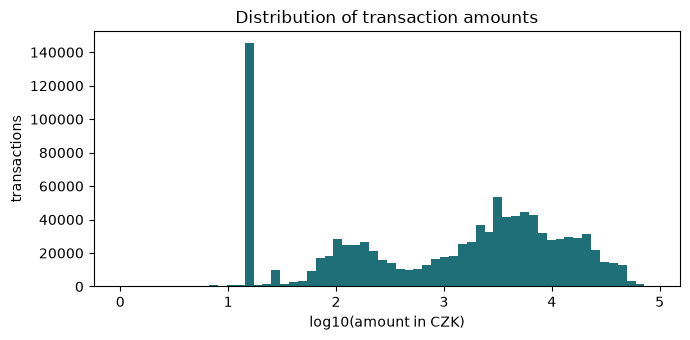

In [33]:
positive = trans.loc[trans["amount"] > 0, "amount"]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(np.log10(positive), bins=60, color="#1f6f78")
ax.set_xlabel("log10(amount in CZK)")
ax.set_ylabel("transactions")
ax.set_title("Distribution of transaction amounts")
plt.tight_layout()
plt.show()

### Testing our hypotheses about the blanks
From the version comparison we expect:
1. `operation` is blank exactly on the interest (`k_symbol = UROK`) rows.
2. `k_symbol` has **two** kinds of "none": truly missing, and a single space.
3. `bank` is present only together with a real partner `account`; `account = 0` appears only where `bank` is blank.

We test each one instead of assuming it.

In [34]:
op_missing = trans["operation"].isna()
is_interest = trans["k_symbol"].eq("UROK")
print("operation blank  vs  k_symbol = UROK")
display(pd.crosstab(op_missing.rename("operation blank"), is_interest.rename("k_symbol = UROK")))
check("operation is blank exactly on the UROK (interest) rows", (op_missing == is_interest).all(), hard=False)

operation blank  vs  k_symbol = UROK


k_symbol = UROK,False,True
operation blank,,
False,873206,0
True,0,183114


[PASS] operation is blank exactly on the UROK (interest) rows


In [35]:
k_state = pd.Series(
    np.select(
        [trans["k_symbol"].isna(), trans["k_symbol"].eq(" ")],
        ["missing", "single space"],
        default="has a value",
    ),
    index=trans.index,
    name="k_symbol state",
)
print("k_symbol state by transaction type")
display(pd.crosstab(trans["type"], k_state))
print("\nk_symbol state by operation")
display(pd.crosstab(trans["operation"].astype(object).fillna("(blank)"), k_state))

k_symbol state by transaction type


k_symbol state,has a value,missing,single space
type,,,
PRIJEM,213452,191631,0
VYBER,0,16666,0
VYDAJ,307554,273584,53433



k_symbol state by operation


k_symbol state,has a value,missing,single space
operation,,,
(blank),183114,0,0
PREVOD NA UCET,147311,8155,52817
PREVOD Z UCTU,30338,34888,0
VKLAD,0,156743,0
VYBER,160243,274059,616
VYBER KARTOU,0,8036,0


In [36]:
bank_present = trans["bank"].notna()
account_real = trans["account"].notna() & trans["account"].ne(0)
counterparty = pd.Series(
    np.select(
        [
            bank_present & account_real,
            ~bank_present & trans["account"].eq(0),
            ~bank_present & trans["account"].isna(),
        ],
        ["bank and real account", "no bank, account = 0", "no bank, no account"],
        default="other combination",
    ),
    index=trans.index,
    name="counterparty state",
)
print("Counterparty (bank / partner account) patterns")
display(counterparty.value_counts().rename("rows").to_frame())
check("bank and partner account always appear together; 0 only where bank is blank", (counterparty == "other combination").sum() == 0, hard=False)

print("\nCounterparty pattern by operation")
display(pd.crosstab(trans["operation"].astype(object).fillna("(blank)"), counterparty))

Counterparty (bank / partner account) patterns


,rows
counterparty state,
"no bank, no account",760931
bank and real account,273508
"no bank, account = 0",21881


[PASS] bank and partner account always appear together; 0 only where bank is blank

Counterparty pattern by operation


counterparty state,bank and real account,"no bank, account = 0","no bank, no account"
operation,,,
(blank),0,0,183114
PREVOD NA UCET,208282,0,1
PREVOD Z UCTU,65226,0,0
VKLAD,0,0,156743
VYBER,0,13845,421073
VYBER KARTOU,0,8036,0


## 5. Does the running balance follow from the amounts?
If a credit (`PRIJEM`) adds and a debit (`VYDAJ`, `VYBER`) subtracts, each balance should equal the previous balance of the same account plus the signed amount, and the first row should equal its own signed amount. The order of transactions within an account matters, so we try two orderings.

In [37]:
def reconcile(order_cols):
    t = trans.sort_values(["account_id"] + order_cols, kind="mergesort")
    signed = np.where(t["type"].eq("PRIJEM"), t["amount"], -t["amount"])
    previous = t.groupby("account_id")["balance"].shift(1)
    expected = np.where(previous.isna(), signed, previous + signed)
    gap = (t["balance"] - expected).round(2)
    return t.assign(signed_amount=signed, expected_balance=expected, balance_gap=gap)


results = {}
for label, cols in {"date, then trans_id": ["date", "trans_id"], "trans_id only": ["trans_id"]}.items():
    rec = reconcile(cols)
    ok = rec["balance_gap"].abs() <= 0.01
    results[label] = rec
    print(
        f"Ordered by {label}: {ok.mean():.4%} of rows reconcile; "
        f"{int((~ok).sum()):,} rows in {rec.loc[~ok, 'account_id'].nunique():,} accounts have a gap"
    )

best_label = max(results, key=lambda k: (results[k]["balance_gap"].abs() <= 0.01).mean())
rec = results[best_label]
check(
    f"Running balance = previous balance + signed amount (ordering: {best_label})",
    (rec["balance_gap"].abs() <= 0.01).all(),
    f"{int((rec['balance_gap'].abs() > 0.01).sum()):,} rows do not reconcile",
    hard=False,
)

print("\nFirst transaction of each account, by operation:")
display(rec.groupby("account_id").head(1)["operation"].value_counts(dropna=False).rename("accounts").to_frame())

gaps = rec[rec["balance_gap"].abs() > 0.01]
if len(gaps):
    print("\nExamples of rows that do not reconcile:")
    display(gaps[["trans_id", "account_id", "date", "type", "operation", "amount", "balance", "expected_balance", "balance_gap"]].head(8))

Ordered by date, then trans_id: 49.6034% of rows reconcile; 532,349 rows in 4,452 accounts have a gap
Ordered by trans_id only: 1.9765% of rows reconcile; 1,035,442 rows in 4,453 accounts have a gap
[FINDING] Running balance = previous balance + signed amount (ordering: date, then trans_id)  (532,349 rows do not reconcile)

First transaction of each account, by operation:


,accounts
operation,
VKLAD,4500
PREVOD NA UCET,0
PREVOD Z UCTU,0
VYBER,0
VYBER KARTOU,0



Examples of rows that do not reconcile:


,trans_id,account_id,date,type,operation,amount,balance,expected_balance,balance_gap
122,159,1,1995-08-31,VYDAJ,VYBER,15,21487,"21,388.00",99.00
918986,3530442,1,1995-08-31,PRIJEM,NaN,99,21502,"21,586.00",-84.00
46,58,1,1995-09-05,VYDAJ,PREVOD NA UCET,2452,19035,"19,050.00",-15.00
123,160,1,1995-09-30,VYDAJ,VYBER,15,22091,"21,999.00",92.00
918987,3530443,1,1995-09-30,PRIJEM,NaN,92,22106,"22,183.00",-77.00
47,59,1,1995-10-05,VYDAJ,PREVOD NA UCET,2452,19639,"19,654.00",-15.00
124,161,1,1995-10-31,VYDAJ,VYBER,15,20494,"20,403.00",91.00
918988,3530444,1,1995-10-31,PRIJEM,NaN,91,20509,"20,585.00",-76.00


### 5b. An order-independent check: does the balance reconcile **day by day**?
The row-by-row check above depends on the order of transactions *within the same day*, and `trans_id` is not a reliable order (interest rows carry much larger IDs than other rows). The examples above suggest that on days with two postings the balance only makes sense if the interest credit comes first.

A check that does not need the within-day order: the balance at the end of a day must equal the running total of all signed amounts up to and including that day. So on every account-day, at least one row's `balance` must equal that running total. We also test whether "interest credits first" repairs the row-by-row check.

**Caution:** this cumulative check *cascades*. One break (for example a missing transaction) makes every later day of that account fail, so a low percentage shows that breaks exist, not how many. Section 5c adds a local check that does not cascade.

In [38]:
t = trans.assign(signed=np.where(trans["type"].eq("PRIJEM"), trans["amount"], -trans["amount"]))
t["is_vyber_type"] = t["type"].eq("VYBER")

daily_net = t.groupby(["account_id", "date"])["signed"].sum()
end_of_day = daily_net.groupby(level="account_id").cumsum().rename("expected_end_of_day")
t = t.join(end_of_day, on=["account_id", "date"])
t["is_end_of_day_balance"] = (t["balance"] - t["expected_end_of_day"]).abs() <= 0.01

day = t.groupby(["account_id", "date"]).agg(
    rows=("trans_id", "size"),
    reconciles=("is_end_of_day_balance", "any"),
    has_vyber_type=("is_vyber_type", "any"),
)
bad_days = day[~day["reconciles"]]

print(f"Account-days: {len(day):,}")
print(f"End-of-day balance reconciles on {day['reconciles'].mean():.4%} of account-days")
print(f"Account-days that do not reconcile: {len(bad_days):,} (in {bad_days.index.get_level_values('account_id').nunique():,} accounts)")
print(f"Days containing a type=VYBER row reconcile on {day.loc[day['has_vyber_type'], 'reconciles'].mean():.4%} (tests that VYBER is a debit)")
print("\nShare of account-days that reconcile, by number of rows on that day (3 = three or more):")
display(day.groupby(day["rows"].clip(upper=3))["reconciles"].agg(account_days="size", share_reconciling="mean"))
check(
    "End-of-day balance equals the running total of signed amounts",
    day["reconciles"].all(),
    f"{len(bad_days):,} of {len(day):,} account-days do not reconcile",
    hard=False,
)


def reconcile_rows(frame, order_cols):
    f = frame.sort_values(["account_id"] + order_cols, kind="mergesort")
    previous = f.groupby("account_id")["balance"].shift(1)
    expected = np.where(previous.isna(), f["signed"], previous + f["signed"])
    return (f["balance"] - expected).abs() <= 0.01


t["interest_first"] = (~t["k_symbol"].eq("UROK")).astype(int)  # 0 for interest credits, so they sort first
print("\nRow-by-row reconciliation under different orderings within a day:")
for label, cols in {
    "date, trans_id": ["date", "trans_id"],
    "date, interest credits first, trans_id": ["date", "interest_first", "trans_id"],
}.items():
    ok = reconcile_rows(t, cols)
    print(f"  {label}: {ok.mean():.4%} of rows reconcile ({int((~ok).sum()):,} rows do not)")

Account-days: 814,768
End-of-day balance reconciles on 11.7570% of account-days
Account-days that do not reconcile: 718,976 (in 4,445 accounts)
Days containing a type=VYBER row reconcile on 10.5136% (tests that VYBER is a debit)

Share of account-days that reconcile, by number of rows on that day (3 = three or more):


,account_days,share_reconciling
rows,,
1,594656,0.13
2,200875,0.07
3,19237,0.08


[FINDING] End-of-day balance equals the running total of signed amounts  (718,976 of 814,768 account-days do not reconcile)

Row-by-row reconciliation under different orderings within a day:
  date, trans_id: 49.6034% of rows reconcile (532,349 rows do not)
  date, interest credits first, trans_id: 82.9806% of rows reconcile (179,779 rows do not)


### 5c. A local, order-independent check, and where the remaining gaps come from
Instead of comparing with a running total from the start, compare each account-day only with the **previous** account-day: some balance of the previous day, plus this day's net amount, must equal some balance of this day. One break then affects only its own day.

Then we look at the rows that still fail under the "interest credits first" order. The **first** failing row of each account is the most informative one, because every row before it reconciled: if it sits on a day with several postings the cause is probably the within-day order, if it sits on a single-posting day the data has a genuine break.

In [39]:
# --- A. Local check: previous day's balance + this day's net = this day's balance ---
days = daily_net.rename("net").reset_index().sort_values(["account_id", "date"])
days["prev_date"] = days.groupby("account_id")["date"].shift(1)

ends = t[["account_id", "date", "balance"]].rename(columns={"balance": "end_candidate"})
starts = t[["account_id", "date", "balance"]].rename(columns={"date": "prev_date", "balance": "start_candidate"})

pairs = ends.merge(days[["account_id", "date", "prev_date", "net"]], on=["account_id", "date"])
pairs = pairs.merge(starts, on=["account_id", "prev_date"], how="left")
pairs["start_candidate"] = pairs["start_candidate"].where(pairs["prev_date"].notna(), 0.0)  # before the first posting the balance is 0
pairs["ok"] = (pairs["start_candidate"] + pairs["net"] - pairs["end_candidate"]).abs() <= 0.01
day["locally_consistent"] = pairs.groupby(["account_id", "date"])["ok"].any()
bad_local = day[~day["locally_consistent"]]

print(f"Account-days consistent with the previous day: {day['locally_consistent'].mean():.4%} of {len(day):,}")
print(f"Inconsistent account-days: {len(bad_local):,} in {bad_local.index.get_level_values('account_id').nunique():,} accounts")
display(day.groupby(day["rows"].clip(upper=3))["locally_consistent"].agg(account_days="size", share_consistent="mean"))
check(
    "Each account-day is consistent with the previous one (order-independent)",
    day["locally_consistent"].all(),
    f"{len(bad_local):,} of {len(day):,} account-days are not",
    hard=False,
)

# --- B. Where do the row-by-row gaps remain after putting interest credits first? ---
f = t.sort_values(["account_id", "date", "interest_first", "trans_id"], kind="mergesort")
previous_balance = f.groupby("account_id")["balance"].shift(1)
f = f.assign(expected=np.where(previous_balance.isna(), f["signed"], previous_balance + f["signed"]))
f["gap"] = (f["balance"] - f["expected"]).round(2)
f["fails"] = f["gap"].abs() > 0.01
f = f.join(day["rows"].rename("rows_that_day"), on=["account_id", "date"])

print("\nFailing rows by number of rows on that day (3 = three or more):")
display(f.groupby(f["rows_that_day"].clip(upper=3))["fails"].agg(rows="size", share_failing="mean"))

first_fail = f[f["fails"]].groupby("account_id").head(1)
print(f"Accounts with at least one failing row: {first_fail['account_id'].nunique():,} of {f['account_id'].nunique():,}")
print("\nFirst failing row of each account, by number of rows on that day:")
display(first_fail["rows_that_day"].clip(upper=3).value_counts().sort_index().rename("accounts").to_frame())
print("First failing rows by type and k_symbol:")
display(first_fail.groupby(["type", "k_symbol"], observed=True, dropna=False).size().rename("accounts").to_frame().query("accounts > 0"))
print("Size of the gap on those first failing rows (balance minus expected):")
display(first_fail["gap"].describe(percentiles=[0.05, 0.5, 0.95]).to_frame().T)

cols = ["trans_id", "account_id", "date", "type", "operation", "k_symbol", "amount", "balance", "expected", "gap"]
for _, r in first_fail.head(3).iterrows():
    same_day = f[(f["account_id"] == r["account_id"]) & (f["date"] == r["date"])]
    before = f[(f["account_id"] == r["account_id"]) & (f["date"] < r["date"])].tail(1)
    print(f"\nAccount {int(r['account_id'])}: last row before, then the rows on {r['date'].date()}")
    display(pd.concat([before, same_day])[cols])

Account-days consistent with the previous day: 92.1293% of 814,768
Inconsistent account-days: 64,128 in 4,445 accounts


,account_days,share_consistent
rows,,
1,594656,0.99
2,200875,0.74
3,19237,0.72


[FINDING] Each account-day is consistent with the previous one (order-independent)  (64,128 of 814,768 account-days are not)

Failing rows by number of rows on that day (3 = three or more):


,rows,share_failing
rows_that_day,,
1,594656,0.04
2,401750,0.31
3,59914,0.55


Accounts with at least one failing row: 4,448 of 4,500

First failing row of each account, by number of rows on that day:


,accounts
rows_that_day,
1,1961
2,2240
3,247


... (6 outputs left out)


Account 2: last row before, then the rows on 1993-04-30


,trans_id,account_id,date,type,operation,k_symbol,amount,balance,expected,gap
533,698,2,1993-04-27,VYDAJ,VYBER,NaN,11000,34286,"34,286.00",0.00
919028,3530484,2,1993-04-30,PRIJEM,NaN,UROK,110,34395,"34,396.00",-1.00



Account 3: last row before, then the rows on 1997-09-30


,trans_id,account_id,date,type,operation,k_symbol,amount,balance,expected,gap
605,846,3,1997-09-11,PRIJEM,VKLAD,NaN,7502,29009,"29,009.00",0.00
919099,3530555,3,1997-09-30,PRIJEM,NaN,UROK,114,29122,"29,123.00",-1.00


### 5d. Are the remaining differences rounding noise or real breaks?
In the first failing rows the typical gap is 1 and most of them are interest or fee rows. That looks like rounding (amounts and balances stored as whole numbers while interest and fees are really fractional), but it is only a hypothesis. This section measures it:
- Are `amount` and `balance` whole numbers?
- How big is the best-case difference of each account-day (smallest `previous balance + net - end balance` over the possible previous and end balances)? Rounding should produce differences of 1 or 2, not hundreds.
- Which differences are large, and do they repeat at the same value (a standing payment that is missing or posted twice)?

In [40]:
# --- A. Are the values whole numbers? ---
for col in ["amount", "balance"]:
    print(f"{col}: dtype {trans[col].dtype}, whole numbers in {(trans[col] % 1 == 0).mean():.2%} of rows")

# --- B. Size of the best-case difference for every account-day ---
pairs["resid"] = pairs["start_candidate"] + pairs["net"] - pairs["end_candidate"]
pairs["abs_resid"] = pairs["resid"].abs()
best = pairs.loc[pairs.groupby(["account_id", "date"])["abs_resid"].idxmin()].set_index(["account_id", "date"])
best["rows"] = day["rows"]

labels = ["exact (<= 0.01)", "up to 1", "1 to 2", "2 to 5", "5 to 100", "over 100"]
bucket = pd.cut(best["abs_resid"], [-0.001, 0.01, 1.0, 2.0, 5.0, 100.0, np.inf], labels=labels)
overall = bucket.value_counts(sort=False).rename("account_days").to_frame()
overall["percent"] = overall["account_days"] / overall["account_days"].sum() * 100
print("\nBest-case difference per account-day:")
display(overall)
print("Percent of account-days in each bucket, by number of rows on that day:")
display((pd.crosstab(best["rows"].clip(upper=3), bucket, normalize="index") * 100).round(2))

# --- C. Row-by-row (interest credits first) with a tolerance for rounding ---
print("\nRow-by-row reconciliation with different tolerances:")
for tol in [0.01, 1.0, 2.0]:
    print(f"  tolerance {tol}: {(f['gap'].abs() <= tol).mean():.4%} of rows reconcile")
large_rows = f[f["gap"].abs() > 1.0]
print(f"Rows with a gap above 1: {len(large_rows):,} in {large_rows['account_id'].nunique():,} accounts. By type and k_symbol:")
display(large_rows.groupby(["type", "k_symbol"], observed=True, dropna=False).size().rename("rows").to_frame().query("rows > 0"))

# --- D. The large differences ---
large = best[best["abs_resid"] > 5]
print(f"\nAccount-days with a difference above 5: {len(large):,} ({len(large) / len(best):.2%}) in {large.index.get_level_values('account_id').nunique():,} accounts")
print("Most common values of (expected end balance - recorded end balance) among them:")
display(large["resid"].round(2).value_counts().head(10).rename("account_days").to_frame())
check(
    "Account-days whose difference is not explained by rounding (above 5)",
    len(large) == 0,
    f"{len(large):,} of {len(best):,} account-days",
    hard=False,
)

first_large = large.reset_index().sort_values(["account_id", "date"]).groupby("account_id").head(1)
show = ["trans_id", "date", "type", "operation", "k_symbol", "amount", "balance"]
for _, r in first_large.head(3).iterrows():
    window = t[(t["account_id"] == r["account_id"]) & (t["date"] <= r["date"])].sort_values(["date", "interest_first", "trans_id"]).tail(6)
    print(f"\nAccount {int(r['account_id'])}: the last rows up to the first large difference ({r['date'].date()}, difference {r['resid']:,.2f})")
    display(window[show])

amount: dtype int64, whole numbers in 100.00% of rows
balance: dtype int64, whole numbers in 100.00% of rows

Best-case difference per account-day:


,account_days,percent
abs_resid,,
exact (<= 0.01),750640,92.13
up to 1,64062,7.86
1 to 2,65,0.01
2 to 5,1,0.00
5 to 100,0,0.00
over 100,0,0.00


Percent of account-days in each bucket, by number of rows on that day:


abs_resid,exact (<= 0.01),up to 1,1 to 2,2 to 5
rows,,,,
1,98.88,1.12,0.00,0.00
2,74.06,25.94,0.00,0.00
3,72.24,27.42,0.34,0.01



Row-by-row reconciliation with different tolerances:
  tolerance 0.01: 82.9806% of rows reconcile
  tolerance 1.0: 92.5514% of rows reconcile
  tolerance 2.0: 92.5582% of rows reconcile
Rows with a gap above 1: 78,681 in 3,904 accounts. By type and k_symbol:


rows
type   k_symbol          
PRIJEM DUCHOD         553
       UROK         10976
       NaN          11120
VYBER  NaN           1456
VYDAJ                7456
       POJISTNE      3269
       SANKC. UROK    740
       SIPO          9470
       SLUZBY        6823
       UVER          1704
       NaN          25114


Account-days with a difference above 5: 0 (0.00%) in 0 accounts
Most common values of (expected end balance - recorded end balance) among them:


,account_days
resid,


[PASS] Account-days whose difference is not explained by rounding (above 5)  (0 of 814,768 account-days)


## 6. Duplicates: exact duplicates versus legitimate repeats
`trans_id` is unique, so no row is a duplicate **by ID**. But two genuine transactions can look identical (same account, day, type, amount ...). We measure how many there are and test whether they behave like separate transactions (each one moves the balance). **Nothing is deleted here.**

In [41]:
check("trans_id is unique (no duplicate transaction IDs)", trans["trans_id"].is_unique)

DUP_COLS = ["account_id", "date", "type", "operation", "amount", "k_symbol", "bank", "account"]
dup_mask = trans.duplicated(subset=DUP_COLS, keep=False)
dups = trans[dup_mask]
n_groups = dups.groupby(DUP_COLS, observed=True, dropna=False).ngroups if len(dups) else 0
check("Rows identical in every column except trans_id", len(dups) == 0, f"{len(dups):,} rows in {n_groups:,} groups", hard=False)

if len(dups):
    sizes = dups.groupby(DUP_COLS, observed=True, dropna=False).size()
    print("Group sizes (rows per identical-looking group):", sizes.value_counts().sort_index().to_dict())
    print("\nBy operation:")
    display(dups["operation"].value_counts(dropna=False).head(10).rename("rows").to_frame())
    follows = rec.loc[dups.index, "balance_gap"].abs() <= 0.01
    print(f"Share of these rows whose balance follows the previous balance: {follows.mean():.2%}")
    print("\nSample (sorted by account and date):")
    display(dups.sort_values(["account_id", "date", "trans_id"]).head(10))

[PASS] trans_id is unique (no duplicate transaction IDs)
[FINDING] Rows identical in every column except trans_id  (3,448 rows in 1,723 groups)
Group sizes (rows per identical-looking group): {2: 1721, 3: 2}

By operation:


,rows
operation,
NaN,2772
VYBER,637
VYBER KARTOU,33
VKLAD,6
PREVOD NA UCET,0
PREVOD Z UCTU,0


Share of these rows whose balance follows the previous balance: 20.13%

Sample (sorted by account and date):


,trans_id,account_id,date,type,operation,amount,balance,k_symbol,bank,account
878893,3445002,19,1995-04-30,PRIJEM,NaN,47,16186,UROK,NaN,NaN
1055309,3681168,19,1995-04-30,PRIJEM,NaN,47,16233,UROK,NaN,NaN
878894,3445003,19,1995-05-31,PRIJEM,NaN,125,36023,UROK,NaN,NaN
1055310,3681169,19,1995-05-31,PRIJEM,NaN,125,35897,UROK,NaN,NaN
878895,3445004,19,1995-06-30,PRIJEM,NaN,207,56245,UROK,NaN,NaN
1055311,3681170,19,1995-06-30,PRIJEM,NaN,207,56038,UROK,NaN,NaN
878896,3445005,19,1995-07-31,PRIJEM,NaN,237,58158,UROK,NaN,NaN
1055312,3681171,19,1995-07-31,PRIJEM,NaN,237,57921,UROK,NaN,NaN
878898,3445007,19,1995-09-30,PRIJEM,NaN,98,16840,UROK,NaN,NaN
1055314,3681173,19,1995-09-30,PRIJEM,NaN,98,16938,UROK,NaN,NaN


### 6b. Do the identical-looking rows each move the balance?
If two identical-looking rows are genuine separate postings, their balances are spaced by the amount: the second posting moves the balance by one more `amount`. If one were a phantom copy, both rows would show the same balance. We test the spacing for every group, and also whether the days containing such rows are consistent with the previous day.

In [42]:
t["in_dup_group"] = dup_mask
day["has_duplicate_group"] = t.groupby(["account_id", "date"])["in_dup_group"].any()
subset = day[day["has_duplicate_group"]]
print(f"Account-days containing identical-looking rows: {len(subset):,} in {subset.index.get_level_values('account_id').nunique():,} accounts")
print(f"  consistent with the previous day: {subset['locally_consistent'].mean():.4%}   (all account-days: {day['locally_consistent'].mean():.4%})")

if len(dups):
    d = dups.assign(group=dups.groupby(DUP_COLS, observed=True, dropna=False).ngroup()).sort_values(["group", "balance"])
    d["step"] = d.groupby("group")["balance"].diff()
    steps = d.dropna(subset=["step"]).copy()
    steps["exact"] = (steps["step"] - steps["amount"]).abs() <= 0.01
    steps["within_1"] = (steps["step"] - steps["amount"]).abs() <= 1.0
    steps["same_balance"] = (steps["step"].abs() <= 0.01) & (steps["amount"] > 0)  # a phantom copy would leave the balance unchanged
    per_group = steps.groupby("group").agg(exact=("exact", "all"), within_1=("within_1", "all"), same_balance=("same_balance", "any"))
    print(f"\nGroups: {len(per_group):,}")
    print(f"  balances spaced by exactly the amount:      {per_group['exact'].mean():.2%}")
    print(f"  balances spaced by the amount, within 1:    {per_group['within_1'].mean():.2%}")
    print(f"  members with the SAME balance (phantom?):   {per_group['same_balance'].mean():.2%}")
    info = d.groupby("group")[["type", "k_symbol"]].first().join(per_group)
    display(
        info.groupby(["type", "k_symbol"], observed=True, dropna=False)
        .agg(groups=("exact", "size"), spaced_exactly=("exact", "mean"), spaced_within_1=("within_1", "mean"), same_balance=("same_balance", "mean"))
        .query("groups > 0")
    )

Account-days containing identical-looking rows: 1,665 in 326 accounts
  consistent with the previous day: 56.2162%   (all account-days: 92.1293%)

Groups: 1,723
  balances spaced by exactly the amount:      74.11%
  balances spaced by the amount, within 1:    94.54%
  members with the SAME balance (phantom?):   0.23%


groups  spaced_exactly  spaced_within_1  same_balance
type   k_symbol                                                          
PRIJEM UROK           1386            0.74             0.97          0.00
       NaN               3            1.00             1.00          0.00
VYDAJ  SANKC. UROK     162            0.55             0.72          0.02
       NaN             172            0.94             0.94          0.00

## 7. Loans: testing claims from the repository's dataset page
The dataset page states two things. We test them on our data instead of trusting them:
- Good loans (`A`, `C`) and bad loans (`B`, `D`) are separated by whether the account's balance ever went negative.
- Loans whose start date plus duration reaches 1999-01-01 are still running (`C`, `D`); the others are finished (`A`, `B`).

If the first holds, overdraft measures and loan status are **not independent evidence**.

In [43]:
loan = tables["loan"].copy()
loan["end_date"] = [d + pd.DateOffset(months=int(m)) for d, m in zip(loan["date"], loan["duration"])]
min_balance = trans.groupby("account_id")["balance"].min().rename("min_balance")
loan = loan.merge(min_balance, on="account_id", how="left")
loan["ever_negative_balance"] = loan["min_balance"] < 0
loan["runs_into_1999"] = loan["end_date"] >= pd.Timestamp("1999-01-01")

print("Loan status counts:")
display(loan["status"].value_counts().rename("loans").to_frame())
print("Status vs 'balance ever went negative':")
display(pd.crosstab(loan["status"], loan["ever_negative_balance"]))
print("Status vs 'end date reaches 1999-01-01':")
display(pd.crosstab(loan["status"], loan["runs_into_1999"]))

exceptions_1 = loan[
    (loan["status"].isin(["A", "C"]) & loan["ever_negative_balance"])
    | (loan["status"].isin(["B", "D"]) & ~loan["ever_negative_balance"])
]
exceptions_2 = loan[
    (loan["status"].isin(["A", "B"]) & loan["runs_into_1999"])
    | (loan["status"].isin(["C", "D"]) & ~loan["runs_into_1999"])
]
check("Negative balance ever <-> bad loan (B, D)", len(exceptions_1) == 0, f"{len(exceptions_1):,} exceptions of {len(loan):,} loans", hard=False)
check("End date reaches 1999 <-> running loan (C, D)", len(exceptions_2) == 0, f"{len(exceptions_2):,} exceptions of {len(loan):,} loans", hard=False)

Loan status counts:


,loans
status,
C,403
A,203
D,45
B,31


Status vs 'balance ever went negative':


ever_negative_balance,False,True
status,,
A,203,0
B,0,31
C,403,0
D,0,45


Status vs 'end date reaches 1999-01-01':


runs_into_1999,False,True
status,,
A,203,0
B,31,0
C,0,403
D,0,45


[PASS] Negative balance ever <-> bad loan (B, D)  (0 exceptions of 682 loans)
[PASS] End date reaches 1999 <-> running loan (C, D)  (0 exceptions of 682 loans)


### 7b. How far does "bad loan" overlap with negative balances?
If negative balances occur almost only on loan accounts with status B or D, an "overdraft" measure is mostly a restatement of loan status. We also check **when** the first negative balance happens relative to the loan start.

In [44]:
acc = tables["account"][["account_id"]].merge(min_balance, on="account_id", how="left")
acc["ever_negative_balance"] = acc["min_balance"] < 0
acc["has_loan"] = acc["account_id"].isin(loan["account_id"])
print("Accounts: has a loan vs balance ever negative")
display(pd.crosstab(acc["has_loan"], acc["ever_negative_balance"], margins=True))

penalty = trans[trans["k_symbol"].eq("SANKC. UROK")]
print(f"Penalty-interest rows (SANKC. UROK): {len(penalty):,}; on accounts with a loan: {int(penalty['account_id'].isin(loan['account_id']).sum()):,}")

first_negative = trans[trans["balance"] < 0].groupby("account_id")["date"].min().rename("first_negative_date")
bad = loan[loan["status"].isin(["B", "D"])].merge(first_negative, on="account_id", how="left")
before_loan = int((bad["first_negative_date"] < bad["date"]).sum())
print(f"B/D loans whose first negative balance is BEFORE the loan start: {before_loan:,} of {len(bad):,}")
print(f"B/D loans whose first negative balance is on or after the loan start: {len(bad) - before_loan:,} of {len(bad):,}")

Accounts: has a loan vs balance ever negative


ever_negative_balance,False,True,All
has_loan,,,
False,3606,212,3818
True,606,76,682
All,4212,288,4500


Penalty-interest rows (SANKC. UROK): 1,577; on accounts with a loan: 589
B/D loans whose first negative balance is BEFORE the loan start: 27 of 76
B/D loans whose first negative balance is on or after the loan start: 49 of 76


## 8. Check log

In [45]:
log = pd.DataFrame(checks)
REPORTS.mkdir(exist_ok=True)
log.to_csv(REPORTS / "profiling_checks.csv", index=False)
print(log["status"].value_counts().to_string())
display(log)

failed = log[log["status"] == "FAIL"]
assert failed.empty, f"{len(failed)} hard check(s) failed - see the log above:\n{failed[['check', 'detail']].to_string(index=False)}"
print("\nAll hard checks passed. FINDING rows need a decision in 02_data_cleaning.ipynb.")

status
PASS       46
FINDING     7


,check,status,detail
0,Manifest records the source database,FINDING,no 'database' column: the manifest was written...
1,Manifest lists exactly the 8 'financial' tables,PASS,"['account', 'card', 'client', 'disp', 'distric..."
2,account: row count matches the manifest,PASS,"4,500 rows"
3,account: account_id is unique,PASS,
4,card: row count matches the manifest,PASS,892 rows
5,card: card_id is unique,PASS,
6,client: row count matches the manifest,PASS,"5,369 rows"
7,client: client_id is unique,PASS,
8,disp: row count matches the manifest,PASS,"5,369 rows"
9,disp: disp_id is unique,PASS,



All hard checks passed. FINDING rows need a decision in 02_data_cleaning.ipynb.


## 9. Your findings (write these in your own words before moving on)
1. Which of the three hypotheses about blanks were confirmed, and which were not?
2. Are the identical-looking transactions legitimate repeats? What evidence did you use?
3. Does the balance reconcile, and with which ordering? What does that mean for using `balance`?
4. Do the repository's two claims about loan status hold on this data? What does that mean for the risk analysis?
5. Which cleaning decisions follow from all of this (one line each)?